# Regression errors by realised regime

This is an ex-post diagnostic: the future realised target determines each test regime. It is not a regime known when the forecast was issued.

In [1]:
%matplotlib inline
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from market_risk.modelling.dataset import FEATURES, TARGET_COLUMN, load_model_dataset
from market_risk.evaluation.provenance import verify_saved_evaluation

ROOT = Path.cwd().resolve()
if not (ROOT / 'pyproject.toml').exists():
    ROOT = ROOT.parent
assert (ROOT / 'pyproject.toml').exists(), 'Run from the repository or notebooks directory.'
df = load_model_dataset()
manifest = verify_saved_evaluation(df, ROOT / 'results')
plt.rcParams.update({'figure.dpi': 100, 'axes.grid': True})
print('Verified corrected dataset and evaluation:', manifest['test_years'])

Verified corrected dataset and evaluation: [2022, 2023, 2024, 2025]


In [2]:
regimes = pd.read_csv(ROOT / 'results/regime_evaluation/regimes.csv', parse_dates=['date'])
metrics = pd.read_csv(ROOT / 'results/regime_evaluation/regime_metrics.csv')
regimes['test_year'] = regimes['date'].dt.year
display(regimes.groupby('test_year')[['elevated_threshold', 'stress_threshold']].first())
display(pd.crosstab(regimes['test_year'], regimes['regime']).reindex(columns=['Normal', 'Elevated', 'Stress'], fill_value=0))
display(metrics)

,elevated_threshold,stress_threshold
test_year,,
2022,0.138151,0.248148
2023,0.170875,0.280087
2024,0.166618,0.264915
2025,0.160231,0.256297


regime,Normal,Elevated,Stress
test_year,,,
2022,26,140,85
2023,210,40,0
2024,215,32,5
2025,186,47,17


,model,regime,count,MAE,RMSE,underestimation_rate
0,ridge,Normal,637,0.041742,0.056252,0.238619
1,persistence,Normal,637,0.043056,0.060563,0.406593
2,lightgbm,Normal,637,0.047964,0.061248,0.185243
3,lightgbm,Elevated,259,0.058434,0.084302,0.459459
4,ridge,Elevated,259,0.060954,0.076990,0.613900
5,persistence,Elevated,259,0.065414,0.090634,0.602317
6,lightgbm,Stress,107,0.112305,0.162917,0.616822
7,ridge,Stress,107,0.116293,0.160165,0.757009
8,persistence,Stress,107,0.123334,0.168641,0.766355


Thresholds are the 70th and 90th percentiles of complete purged training targets, recomputed before each year. A target equal to a threshold enters the higher regime. Missing/extra/duplicate dates and inconsistent stored targets are rejected by the evaluation module.

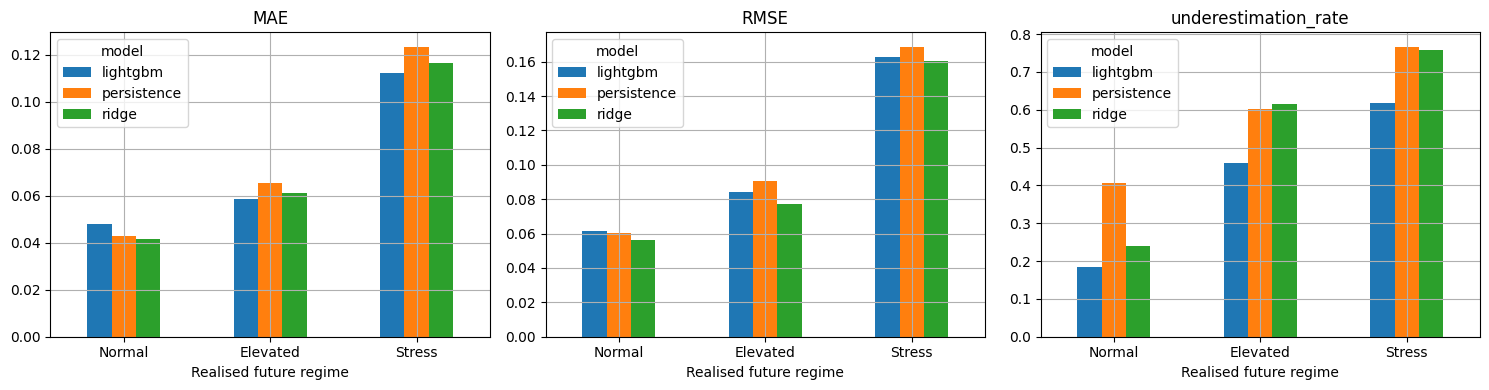

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, metric in zip(axes, ['MAE', 'RMSE', 'underestimation_rate']):
    table = metrics.pivot(index='regime', columns='model', values=metric).reindex(['Normal', 'Elevated', 'Stress'])
    table.plot.bar(ax=ax, rot=0)
    ax.set_title(metric)
    ax.set_xlabel('Realised future regime')
plt.tight_layout()
plt.show()

Positive error means underestimation. A lower underestimation rate can result from systematic overestimation; it does not measure the cost of risk decisions. Most Stress rows occur in 2022 and neighbouring targets overlap. See [results and limitations](../docs/07_results.md).